# Assignment 03: Automotive Data Cleaning and Preprocessing

## Aim
Prepare a deliberately imperfect automotive dataset for machine-learning use by dealing with missing entries, unusual values, categorical data and feature scaling.

## Methods Applied
1. Median/mode imputation
2. IQR-based outlier identification
3. Capping extreme numerical observations
4. One-hot encoding for categorical information
5. Standardization with `StandardScaler`

## Final Goal
Produce a consistent numerical dataset that can be supplied to a downstream ML model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [2]:
np.random.seed(17)

n = 320

mileage = np.random.uniform(
    5000,
    150000,
    n
)

age = np.random.uniform(
    1,
    15,
    n
)

engine = np.random.uniform(
    1.0,
    4.0,
    n
)

price = (
    30000
    - age * 1500
    - mileage * 0.08
    + engine * 3000
    + np.random.normal(0, 1500, n)
)

price = np.clip(
    price,
    2000,
    None
)

fuel = np.random.choice(
    [
        "Petrol",
        "Diesel",
        "Electric"
    ],
    n
)

messy = pd.DataFrame({
    "mileage_km": mileage,
    "age_years": age,
    "engine_size_L": engine,
    "fuel_type": fuel,
    "price": price
})

messy.head()

,mileage_km,age_years,engine_size_L,fuel_type,price
0,47726.425390,2.736842,2.230283,Electric,30245.971431
1,81935.079563,10.784053,3.224424,Diesel,15975.672517
2,32770.514107,7.151542,2.738286,Electric,27180.916150
3,14845.551938,10.181018,3.781020,Diesel,25864.035828
4,119112.891700,12.157305,1.149853,Diesel,5593.071533


In [3]:
missing_indices = np.random.choice(
    n,
    15,
    replace=False
)

messy.loc[
    missing_indices[:5],
    "mileage_km"
] = np.nan

messy.loc[
    missing_indices[5:10],
    "age_years"
] = np.nan

messy.loc[
    missing_indices[10:13],
    "engine_size_L"
] = np.nan

messy.loc[
    missing_indices[13:],
    "fuel_type"
] = np.nan

In [4]:
messy.loc[
    0,
    "price"
] = 200000

messy.loc[
    1,
    "price"
] = 250000

messy.loc[
    2,
    "mileage_km"
] = 500000

messy.loc[
    3,
    "mileage_km"
] = 600000

In [5]:
print("Missing values before cleaning:")

print(
    messy.isna().sum()
)

print("\nDataset description:")

display(
    messy.describe()
)

Missing values before cleaning:
mileage_km       5
age_years        5
engine_size_L    3
fuel_type        2
price            0
dtype: int64

Dataset description:


,mileage_km,age_years,engine_size_L,price
count,315.000000,315.000000,317.000000,320.000000
mean,85129.925455,7.672568,2.527026,20834.730966
std,56075.210989,3.877703,0.833945,17953.211005
min,5319.738555,1.032641,1.005942,2000.000000
25%,44417.858907,4.630504,1.898511,14308.596028
50%,85659.179723,7.619729,2.550011,19693.768237
75%,119205.420779,10.759480,3.226035,25075.814727
max,600000.000000,14.967445,3.994484,250000.000000


In [6]:
num_cols = [
    "mileage_km",
    "age_years",
    "engine_size_L",
    "price"
]

cat_cols = [
    "fuel_type"
]

In [7]:
num_imputer = SimpleImputer(
    strategy="median"
)

cat_imputer = SimpleImputer(
    strategy="most_frequent"
)

clean = messy.copy()

clean[num_cols] = num_imputer.fit_transform(
    clean[num_cols]
)

clean[cat_cols] = cat_imputer.fit_transform(
    clean[cat_cols]
)

In [8]:
print(
    "Missing values after imputation:"
)

print(
    clean.isna().sum()
)

Missing values after imputation:
mileage_km       0
age_years        0
engine_size_L    0
fuel_type        0
price            0
dtype: int64


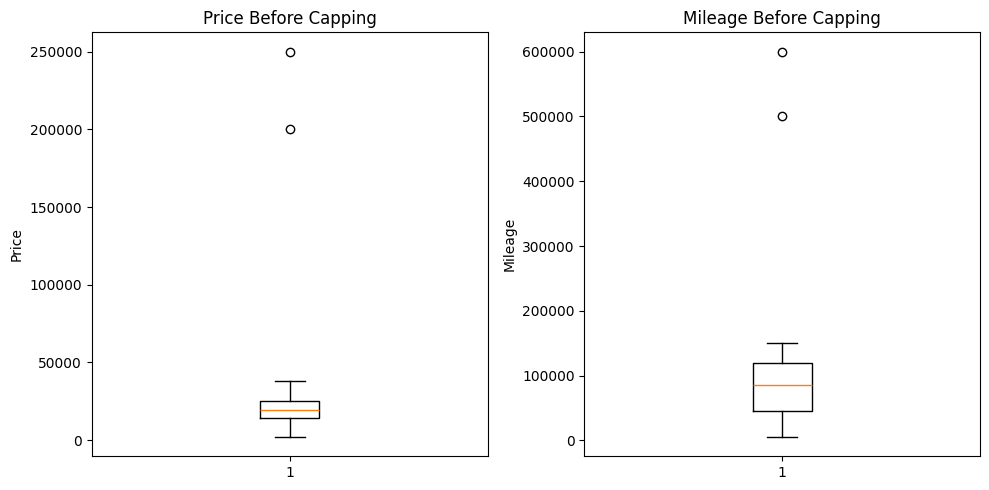

In [9]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.boxplot(
    clean["price"]
)

plt.title(
    "Price Before Capping"
)

plt.ylabel("Price")


plt.subplot(1, 2, 2)

plt.boxplot(
    clean["mileage_km"]
)

plt.title(
    "Mileage Before Capping"
)

plt.ylabel("Mileage")

plt.tight_layout()

plt.show()

In [10]:
def cap_outliers_iqr(
    df,
    col,
    k=1.5
):

    q1, q3 = df[
        col
    ].quantile(
        [0.25, 0.75]
    )

    iqr = q3 - q1

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    n_outliers = (
        (df[col] < lower)
        |
        (df[col] > upper)
    ).sum()

    df[col] = df[
        col
    ].clip(
        lower,
        upper
    )

    return n_outliers

In [11]:
for col in [
    "price",
    "mileage_km"
]:

    count = cap_outliers_iqr(
        clean,
        col
    )

    print(
        f"{col}: "
        f"{count} outliers capped"
    )

price: 2 outliers capped
mileage_km: 2 outliers capped


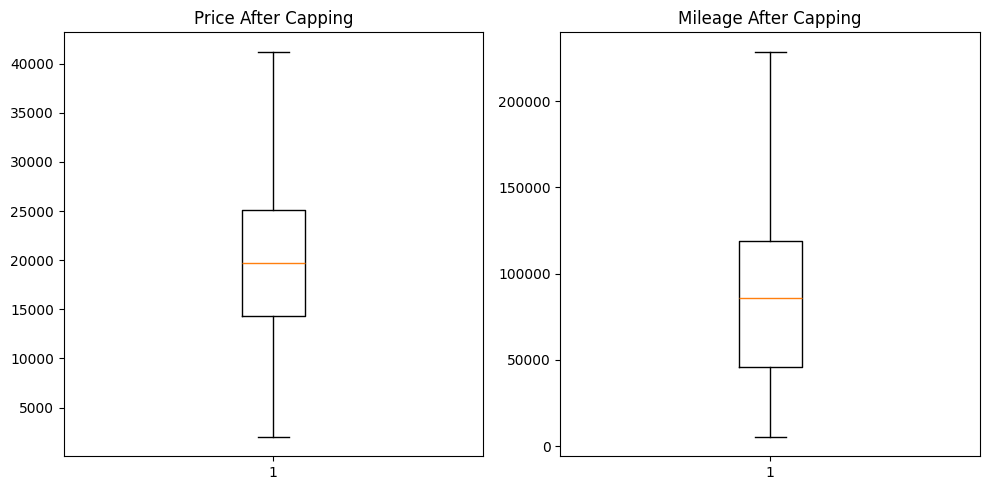

In [12]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.boxplot(
    clean["price"]
)

plt.title(
    "Price After Capping"
)


plt.subplot(1, 2, 2)

plt.boxplot(
    clean["mileage_km"]
)

plt.title(
    "Mileage After Capping"
)

plt.tight_layout()

plt.show()

In [13]:
encoder = OneHotEncoder(
    sparse_output=False,
    drop="first"
)

fuel_encoded = pd.DataFrame(
    encoder.fit_transform(
        clean[["fuel_type"]]
    ),
    columns=encoder.get_feature_names_out(
        ["fuel_type"]
    )
)

display(
    fuel_encoded.head()
)

,fuel_type_Electric,fuel_type_Petrol
0,1.0,0.0
1,0.0,0.0
2,1.0,0.0
3,0.0,0.0
4,0.0,0.0


In [14]:
scaler = StandardScaler()

scaled_num = pd.DataFrame(
    scaler.fit_transform(
        clean[num_cols]
    ),
    columns=num_cols
)

display(
    scaled_num.head()
)

,mileage_km,age_years,engine_size_L,price
0,-0.824446,-1.284735,-0.358335,2.824455
1,-0.027830,0.810248,0.841276,2.824455
2,3.390212,-0.135427,0.254663,0.982737
3,3.390212,0.653256,1.512910,0.810063
4,0.837929,1.167756,-1.662068,-1.847927


In [15]:
processed = pd.concat(
    [
        scaled_num,
        fuel_encoded
    ],
    axis=1
)

print(
    "Final model-ready dataset:"
)

display(
    processed.head()
)

print(
    "\nFinal shape:",
    processed.shape
)

Final model-ready dataset:


,mileage_km,age_years,engine_size_L,price,fuel_type_Electric,fuel_type_Petrol
0,-0.824446,-1.284735,-0.358335,2.824455,1.0,0.0
1,-0.027830,0.810248,0.841276,2.824455,0.0,0.0
2,3.390212,-0.135427,0.254663,0.982737,1.0,0.0
3,3.390212,0.653256,1.512910,0.810063,0.0,0.0
4,0.837929,1.167756,-1.662068,-1.847927,0.0,0.0



Final shape: (320, 6)
